# Model 3 (upgraded) - FastSpeech-style Transformer
Same encoder as the baseline Transformer (it starts from those weights), plus a duration predictor, a length regulator and a Transformer decoder. Durations are learned during training with an alignment module (forward-sum loss + monotonic alignment search). Checkpoints are saved as `fastspeech_*` so the baseline `transformer_*` files are kept for comparison.

**Run the cells in order with the ▶ button.** Training auto-resumes if interrupted.

In [1]:
import sys, torch
ROOT = r"C:\Users\INTEL\Downloads\voice_cloning_v2_1\voice_cloning_v2_1"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE - select the Python 3.11.9 kernel")

GPU: NVIDIA GeForce RTX 4070


## Step 1 - train 3 epochs, then check (about 5-10 minutes)

In [2]:
from vc_lib import train_fastspeech
from vc_lib.common import plot_history

hist = train_fastspeech.train(ROOT, epochs=60, stop_after=3)

Training segments: 117072 (skipped 0 with more characters than frames) | validation: 3732
[fastspeech] starting fresh
[fastspeech] epoch 1/3  train=4.2272  mel=0.1210  dur=0.3908  align=3.6908  val=0.1030  val_dur=0.3602  (215s)  * best
[fastspeech] epoch 2/3  train=3.1069  mel=0.0935  dur=0.2764  align=2.7220  val=0.0893  val_dur=0.2440  (211s)  * best
[fastspeech] epoch 3/3  train=2.7853  mel=0.0862  dur=0.2318  align=2.4545  val=0.0809  val_dur=0.2189  (210s)  * best


## Step 2 - early check: is the alignment working?
Each picture should show a **bright line going from bottom-left to top-right** (characters progress through time). `sharpness` should be well above 0.3 and rising. A blurry or flat picture means the alignment hasn't formed yet; paste the numbers and pictures in the chat before continuing.

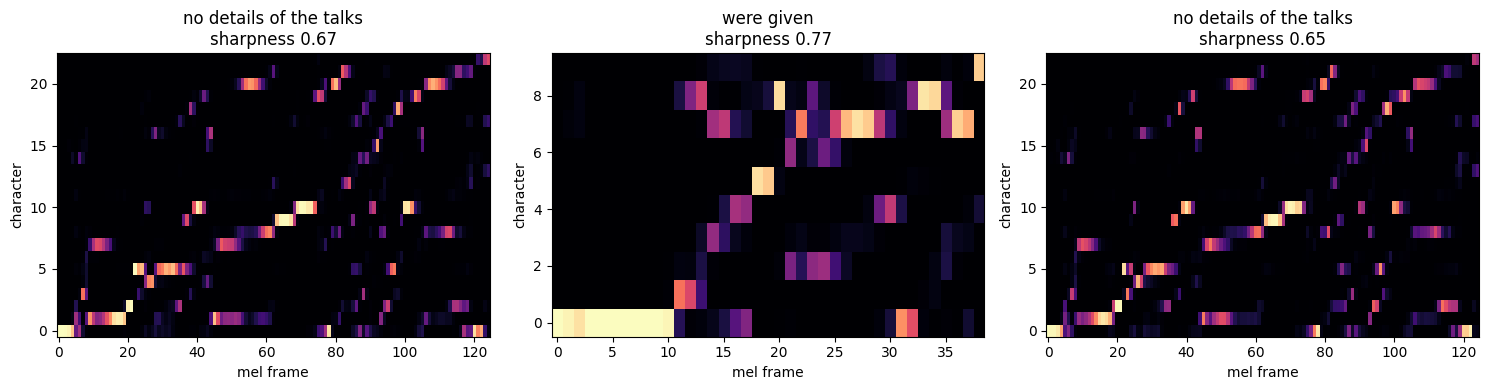

In [3]:
import matplotlib.pyplot as plt
rep = train_fastspeech.alignment_report(ROOT, n=3)
fig, ax = plt.subplots(1, len(rep), figsize=(5 * len(rep), 4))
for a, r in zip(ax, rep):
    a.imshow(r['attn'].T.numpy(), aspect='auto', origin='lower', cmap='magma')
    a.set_title(f"{r['text']}\nsharpness {r['sharpness']:.2f}"); a.set_xlabel('mel frame'); a.set_ylabel('character')
plt.tight_layout(); plt.show()

Can Whisper already hear some words? (No diffusion yet. After 3 epochs, partial words are a good sign.)

In [4]:
from vc_lib.infer import VoicePipeline, evaluate
from vc_lib.common import paths, load_cache
C = load_cache(paths(ROOT))
pipe = VoicePipeline(ROOT, use_diffusion=False, model="fastspeech")
spk = pipe.meta["train_speakers"][0]
rows = [k for k in C["idx"]["val"].tolist() if C["spks"][k] == spk][:5]
evaluate(pipe, [C["texts"][k] for k in rows], speaker=spk)

Text-to-mel model: fastspeech | diffusion: off


c:\Users\INTEL\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


WER 0.20 | similarity 0.79 | 'no details of the talks' -> 'No details of the top.'
WER 1.00 | similarity 0.76 | 'were given' -> ''
WER 0.20 | similarity 0.79 | 'no details of the talks' -> 'No details of the top.'
WER 1.00 | similarity 0.76 | 'were given' -> ''
WER 0.25 | similarity 0.79 | 'overall it was a' -> 'overall it was'

Mean WER: 0.530 (lower is better)   Mean speaker similarity: 0.780


([0.2, 1.0, 0.2, 1.0, 0.25],
 [0.7943758964538574,
  0.757936418056488,
  0.7943758964538574,
  0.757936418056488,
  0.7931544780731201])

## Step 3 - continue training to the end (about 1.5-2.5 hours)
Resumes from epoch 3. When it finishes, it exports the aligned coarse mels for Model 4 (this overwrites `data/coarse_cache.pt`).

Training segments: 117072 (skipped 0 with more characters than frames) | validation: 3732
[fastspeech] resumed at epoch 3 (best val so far 0.0809)
[fastspeech] epoch 4/60  train=2.6180  mel=0.0793  dur=0.2140  align=2.3137  val=0.0787  val_dur=0.2114  (221s)  * best
[fastspeech] epoch 5/60  train=2.4994  mel=0.0765  dur=0.2011  align=2.2115  val=0.0751  val_dur=0.1997  (219s)  * best
[fastspeech] epoch 6/60  train=2.4194  mel=0.0749  dur=0.1926  align=2.1421  val=0.0748  val_dur=0.1875  (213s)  * best
[fastspeech] epoch 7/60  train=2.3666  mel=0.0739  dur=0.1874  align=2.0957  val=0.0735  val_dur=0.1799  (217s)  * best
[fastspeech] epoch 8/60  train=2.3235  mel=0.0730  dur=0.1827  align=2.0583  val=0.0730  val_dur=0.1820  (211s)  * best
[fastspeech] epoch 9/60  train=2.2881  mel=0.0723  dur=0.1785  align=2.0281  val=0.0727  val_dur=0.1748  (221s)  * best
[fastspeech] epoch 10/60  train=2.2583  mel=0.0717  dur=0.1751  align=2.0025  val=0.0731  val_dur=0.1807  (216s)
[fastspeech] epoch 1

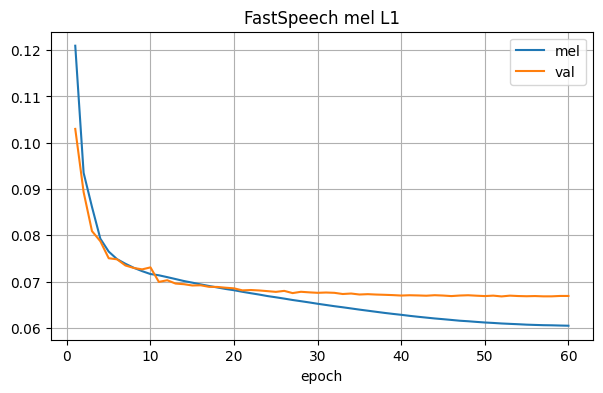

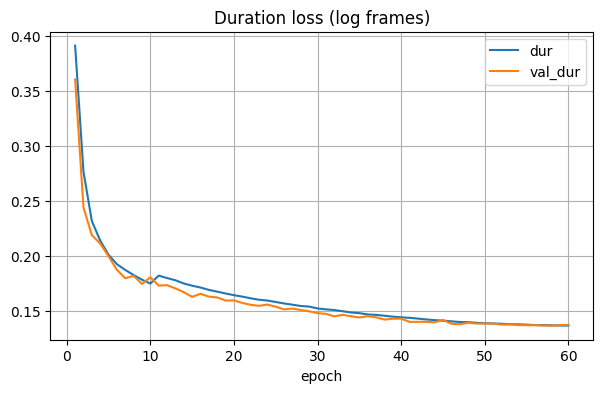

In [5]:
hist = train_fastspeech.train(ROOT, epochs=60)
plot_history(hist, ['mel', 'val'], 'FastSpeech mel L1')
plot_history(hist, ['dur', 'val_dur'], 'Duration loss (log frames)')

If training finished but the export was interrupted, run this cell alone:

In [ ]:
# train_fastspeech.export_coarse(ROOT)

## Step 4 - final check without diffusion

In [6]:
from vc_lib.infer import VoicePipeline, evaluate
from vc_lib.common import paths, load_cache
C = load_cache(paths(ROOT))
pipe = VoicePipeline(ROOT, use_diffusion=False, model="fastspeech")
spk = pipe.meta["train_speakers"][0]
rows = [k for k in C["idx"]["val"].tolist() if C["spks"][k] == spk][:5]
evaluate(pipe, [C["texts"][k] for k in rows], speaker=spk)

Text-to-mel model: fastspeech | diffusion: off
WER 0.20 | similarity 0.79 | 'no details of the talks' -> 'No details of the talk.'
WER 2.00 | similarity 0.79 | 'were given' -> 'Thank you.  Thank you.'
WER 0.20 | similarity 0.79 | 'no details of the talks' -> 'No details of the talk.'
WER 2.00 | similarity 0.79 | 'were given' -> 'Thank you.  Thank you.'
WER 0.00 | similarity 0.77 | 'overall it was a' -> 'Overall, it was a-'

Mean WER: 0.880 (lower is better)   Mean speaker similarity: 0.787


([0.2, 2.0, 0.2, 2.0, 0.0],
 [0.792418360710144,
  0.7907739877700806,
  0.792418360710144,
  0.7907739877700806,
  0.7678784132003784])

In [7]:
import numpy as np, librosa, random
from faster_whisper import WhisperModel
from vc_lib.common import segment_audio, SR
from vc_lib.infer import word_error_rate

wh = WhisperModel("small", device="cuda", compute_type="float16")
def hear(y):
    segs, _ = wh.transcribe(librosa.resample(y, orig_sr=SR, target_sr=16000), language="en", beam_size=1)
    return " ".join(s.text for s in segs).strip()

random.seed(0)
seen, rows = set(), []
for k in random.sample(C["idx"]["val"].tolist(), len(C["idx"]["val"])):
    t = C["texts"][k]
    if len(t.split()) >= 3 and t not in seen and C["spks"][k] in pipe.meta["train_speakers"]:
        seen.add(t); rows.append(k)
    if len(rows) == 30:
        break

synth, real = [], []
for k in rows:
    t, s = C["texts"][k], C["spks"][k]
    synth.append(word_error_rate(t, hear(pipe.synthesize(t, speaker=s))))
    real.append(word_error_rate(t, hear(segment_audio(paths(ROOT), C, k))))
print(f"30 phrases, 3+ words, {len(set(C['spks'][k] for k in rows))} speakers")
print(f"Generated speech WER: {np.mean(synth):.3f}   | perfectly heard: {np.mean(np.array(synth) == 0):.0%}")
print(f"Real recordings WER:  {np.mean(real):.3f}   | perfectly heard: {np.mean(np.array(real) == 0):.0%}  (best possible)")

30 phrases, 3+ words, 25 speakers
Generated speech WER: 0.119   | perfectly heard: 67%
Real recordings WER:  0.172   | perfectly heard: 60%  (best possible)
